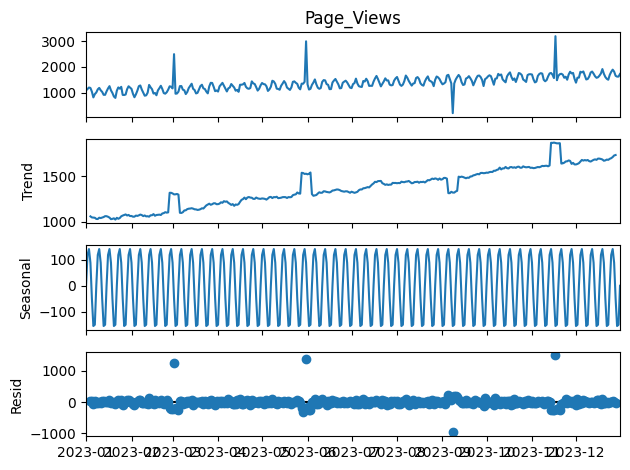

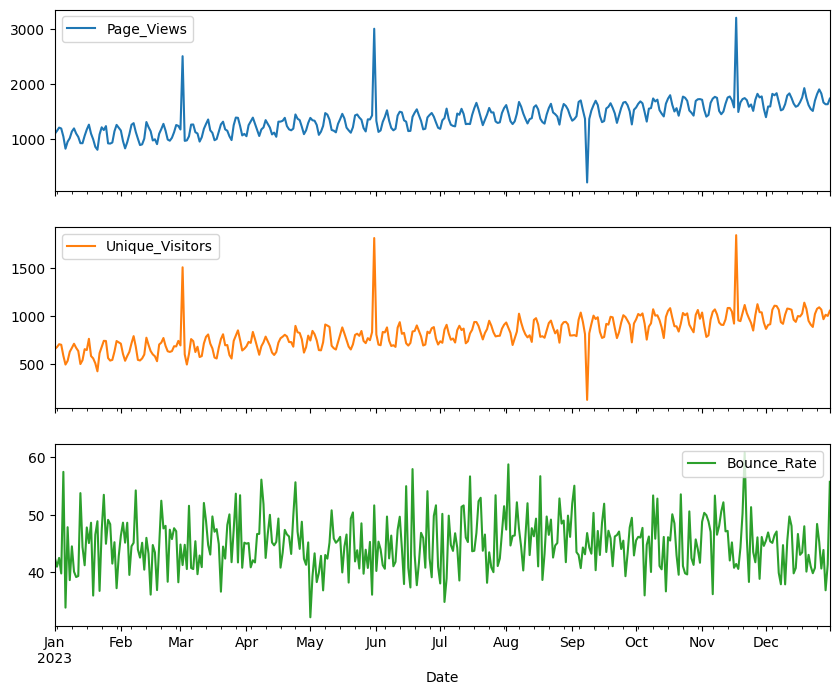

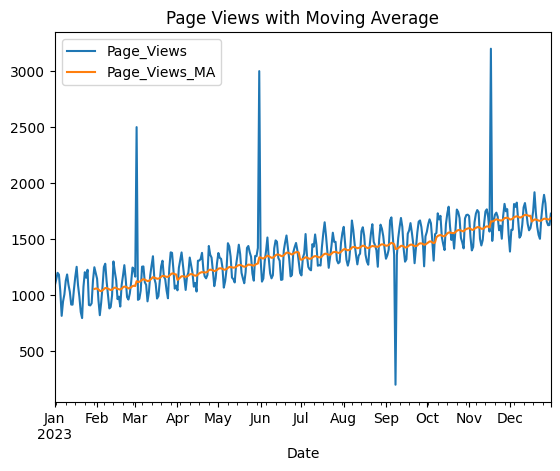

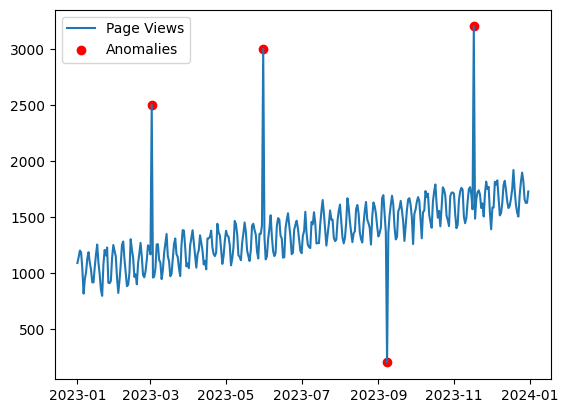

In [1]:
# 6) Time Series Analysis of Website Traffic - To analyze the time series data of website traffic to identify trends, seasonality, and anomalies.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
# Sample daily website traffic data (same columns as website_traffic.csv)
np.random.seed(0)
dates = pd.date_range('2023-01-01', periods=365, freq='D')
t = np.arange(365)
page_views = 1000 + 2 * t + 150 * np.sin(2 * np.pi * t / 7) + np.random.normal(0, 50, 365)
page_views[[60, 150, 250, 320]] = [2500, 3000, 200, 3200]
page_views[[30, 100, 200]] = np.nan
# Load dataset
data = pd.DataFrame({'Date': dates,
'Page_Views': page_views,
'Unique_Visitors': page_views * 0.6 + np.random.normal(0, 30, 365),
'Bounce_Rate': np.random.normal(45, 5, 365)})
data = data.set_index('Date')
# Handle missing values by interpolation
data = data.interpolate()
# Time Series Decomposition
decomposition = seasonal_decompose(data['Page_Views'], model='additive')
decomposition.plot()
plt.show()
# Plot the time series data for Page_Views, Unique_Visitors and Bounce_Rate
data[['Page_Views', 'Unique_Visitors', 'Bounce_Rate']].plot(subplots=True, figsize=(10, 8))
plt.show()
# Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()
# Anomaly Detection
data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()
